<a href="https://colab.research.google.com/github/samirapilfree5-creator/Code-sql/blob/main/TP3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## TP 3 : Data modelling

# Q1 : Représentation vectorielle des données

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

base = "https://raw.githubusercontent.com/EDJINEDJA/Health-Data-modelling/main/lab2/data2/Medical-Abstracts-TC-Corpus-main/"
train = pd.read_csv(base + "medical_tc_train.csv")
test  = pd.read_csv(base + "medical_tc_test.csv")
df = pd.concat([train, test], ignore_index=True)
print(df.shape)

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",   # retire the, of, and...
    min_df=5,               # ignore les mots présents dans moins de 5 documents
    max_df=0.95,            # ignore les mots présents dans plus de 95 % des documents
    sublinear_tf=True,      # atténue l'effet des mots très répétés
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",  # mots alphabétiques uniquement
)
X = vectorizer.fit_transform(df["medical_abstract"])
y = df["condition_label"]

print(X.shape)
print(vectorizer.get_feature_names_out()[:10])

(14438, 2)
(14438, 13108)
['aa' 'aaa' 'aai' 'ab' 'abandoned' 'abbott' 'abbreviated' 'abc' 'abdomen'
 'abdominal']


# Q2 : Transformation en classificatio, binaire

In [2]:
# Nouvelle variable cible binaire : 1 = néoplasique, 0 = non néoplasique
df["y_bin"] = (df["condition_label"] == 1).astype(int)
df["classe_bin"] = df["y_bin"].map({1: "Néoplasique", 0: "Non néoplasique"})

# Vérification de la transformation
print(df.groupby(["condition_label", "classe_bin"]).size())

# Distribution des deux nouvelles classes
print(df["classe_bin"].value_counts())
print(df["classe_bin"].value_counts(normalize=True).round(3))

y_bin = df["y_bin"]

condition_label  classe_bin     
1                Néoplasique        3163
2                Non néoplasique    1494
3                Non néoplasique    1925
4                Non néoplasique    3051
5                Non néoplasique    4805
dtype: int64
classe_bin
Non néoplasique    11275
Néoplasique         3163
Name: count, dtype: int64
classe_bin
Non néoplasique    0.781
Néoplasique        0.219
Name: proportion, dtype: float64


# Q3 : Séparation des données pour l'entrainement

In [3]:
from sklearn.model_selection import train_test_split

# 1. Découpage stratifié des textes bruts (80 % / 20 %)
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["medical_abstract"], df["y_bin"],
    test_size=0.2, stratify=df["y_bin"], random_state=42
)

# 2. TF-IDF ajusté sur le train uniquement, puis appliqué au test
vectorizer = TfidfVectorizer(
    lowercase=True, stop_words="english", min_df=5, max_df=0.95,
    sublinear_tf=True, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
)
X_train = vectorizer.fit_transform(X_train_txt)
X_test  = vectorizer.transform(X_test_txt)

# 3. Vérifications
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Part de néoplasiques - train :", round(y_train.mean(), 3),
      "| test :", round(y_test.mean(), 3))

Train : (11550, 11701) | Test : (2888, 11701)
Part de néoplasiques - train : 0.219 | test : 0.219


# Q4 : Regression logistique

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

# Entraînement sur le train
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

# Probabilité d'être néoplasique (colonne de la classe 1)
proba_test = log_reg.predict_proba(X_test)[:, 1]

# Aperçu : 5 premiers résumés du test
apercu = pd.DataFrame({
    "proba_neoplasique": proba_test[:5].round(3),
    "vraie_classe": y_test.values[:5],
})
print(apercu)

# Décision avec le seuil 0,5, puis évaluation
y_pred = (proba_test >= 0.5).astype(int)
print("Exactitude :", round(accuracy_score(y_test, y_pred), 3))
print("Précision  :", round(precision_score(y_test, y_pred), 3))
print("Rappel     :", round(recall_score(y_test, y_pred), 3))
print("F1         :", round(f1_score(y_test, y_pred), 3))
print("AUC-ROC    :", round(roc_auc_score(y_test, proba_test), 3))
print(confusion_matrix(y_test, y_pred))

   proba_neoplasique  vraie_classe
0              0.039             0
1              0.004             0
2              0.908             1
3              0.340             0
4              0.109             0
Exactitude : 0.867
Précision  : 0.758
Rappel     : 0.575
F1         : 0.654
AUC-ROC    : 0.932
[[2139  116]
 [ 269  364]]


# Q5 : Calcul des odds

In [5]:
import numpy as np

# Cotes calculées à partir des probabilités
odds_test = proba_test / (1 - proba_test)

# Score linéaire du modèle = log(odds)
logit_test = log_reg.decision_function(X_test)

# Vérification : odds = exp(logit)
print("Cohérence :", np.allclose(odds_test, np.exp(logit_test)))

# Tableau récapitulatif sur les 5 premiers résumés
tableau = pd.DataFrame({
    "proba": proba_test[:5].round(3),
    "odds": odds_test[:5].round(3),
    "log_odds": logit_test[:5].round(3),
    "vraie_classe": y_test.values[:5],
})
print(tableau)

# Cote de référence : un résumé « vide » (tous les poids à 0)
print("Odds de base :", np.exp(log_reg.intercept_[0]).round(3))

Cohérence : True
   proba   odds  log_odds  vraie_classe
0  0.039  0.040    -3.207             0
1  0.004  0.004    -5.567             0
2  0.908  9.845     2.287             1
3  0.340  0.516    -0.661             0
4  0.109  0.123    -2.096             0
Odds de base : 0.183


# Q6 : Interprètation

Top 15 - orientent vers NÉOPLASIQUE
         mot  coefficient  facteur_odds
      cancer        8.580      5325.222
       tumor        5.806       332.123
   carcinoma        5.053       156.495
    leukemia        4.289        72.884
      tumors        4.245        69.734
        cell        3.486        32.660
    melanoma        3.336        28.117
   malignant        2.941        18.943
       cells        2.824        16.842
chemotherapy        2.554        12.861
      tumour        2.521        12.439
     tumours        2.432        11.386
      breast        2.285         9.829
   radiation        2.282         9.799
       human        2.037         7.668

Top 15 - orientent vers NON NÉOPLASIQUE
         mot  coefficient  facteur_odds
    coronary       -2.443         0.087
      artery       -2.168         0.114
hypertension       -2.115         0.121
        pain       -2.075         0.126
       acute       -2.063         0.127
     chronic       -2.014         0.134
   

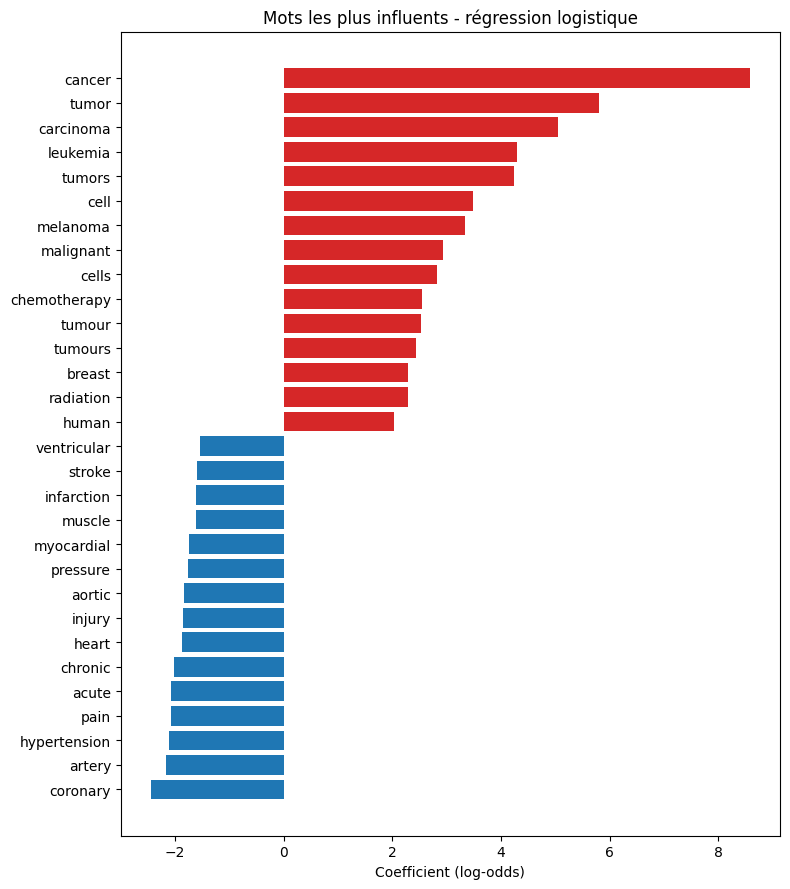

In [6]:
feature_names = vectorizer.get_feature_names_out()
coefs = log_reg.coef_[0]

coef_df = pd.DataFrame({
    "mot": feature_names,
    "coefficient": coefs,
    "facteur_odds": np.exp(coefs),
}).sort_values("coefficient", ascending=False)

print("Top 15 - orientent vers NÉOPLASIQUE")
print(coef_df.head(15).round(3).to_string(index=False))
print("\nTop 15 - orientent vers NON NÉOPLASIQUE")
print(coef_df.tail(15).iloc[::-1].round(3).to_string(index=False))

print("\nMots à coefficient positif :", (coefs > 0).sum(),
      "| négatif :", (coefs < 0).sum())


import matplotlib.pyplot as plt

top = pd.concat([coef_df.head(15), coef_df.tail(15)])
colors = ["tab:red" if c > 0 else "tab:blue" for c in top["coefficient"]]
plt.figure(figsize=(8, 9))
plt.barh(top["mot"], top["coefficient"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("Coefficient (log-odds)")
plt.title("Mots les plus influents - régression logistique")
plt.tight_layout(); plt.show()

# Q7 : Comparaison

In [7]:
from sklearn.svm import LinearSVC
import time

def evaluer(nom, modele):
    t0 = time.time()
    modele.fit(X_train, y_train)
    duree = time.time() - t0
    score = modele.decision_function(X_test)   # score linéaire (log-odds pour LR)
    pred = (score >= 0).astype(int)            # seuil 0 sur le score = seuil 0,5 en proba
    return {
        "Modèle": nom,
        "Exactitude": accuracy_score(y_test, pred),
        "Précision": precision_score(y_test, pred),
        "Rappel": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "AUC-ROC": roc_auc_score(y_test, score),
        "Temps (s)": duree,
    }, confusion_matrix(y_test, pred)

res_lr,  cm_lr  = evaluer("Régression logistique", LogisticRegression(max_iter=1000, random_state=42))
res_svm, cm_svm = evaluer("SVM linéaire", LinearSVC(random_state=42))

comparaison = pd.DataFrame([res_lr, res_svm]).set_index("Modèle").round(3)
print(comparaison)
print(cm_lr); print(cm_svm)

                       Exactitude  Précision  Rappel     F1  AUC-ROC  \
Modèle                                                                 
Régression logistique       0.867      0.758   0.575  0.654    0.932   
SVM linéaire                0.846      0.666   0.596  0.629    0.904   

                       Temps (s)  
Modèle                            
Régression logistique      0.318  
SVM linéaire               0.156  
[[2139  116]
 [ 269  364]]
[[2066  189]
 [ 256  377]]


# Q7 : Comparaison des perfomances SVM et Regression logistique

In [8]:
from sklearn.svm import LinearSVC
import time

def evaluer(nom, modele):
    t0 = time.time()
    modele.fit(X_train, y_train)
    duree = time.time() - t0
    score = modele.decision_function(X_test)   # score linéaire (log-odds pour LR)
    pred = (score >= 0).astype(int)            # seuil 0 sur le score = seuil 0,5 en proba
    return {
        "Modèle": nom,
        "Exactitude": accuracy_score(y_test, pred),
        "Précision": precision_score(y_test, pred),
        "Rappel": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "AUC-ROC": roc_auc_score(y_test, score),
        "Temps (s)": duree,
    }, confusion_matrix(y_test, pred)

res_lr,  cm_lr  = evaluer("Régression logistique", LogisticRegression(max_iter=1000, random_state=42))
res_svm, cm_svm = evaluer("SVM linéaire", LinearSVC(random_state=42))

comparaison = pd.DataFrame([res_lr, res_svm]).set_index("Modèle").round(3)
print(comparaison)
print(cm_lr); print(cm_svm)

                       Exactitude  Précision  Rappel     F1  AUC-ROC  \
Modèle                                                                 
Régression logistique       0.867      0.758   0.575  0.654    0.932   
SVM linéaire                0.846      0.666   0.596  0.629    0.904   

                       Temps (s)  
Modèle                            
Régression logistique      1.067  
SVM linéaire               0.137  
[[2139  116]
 [ 269  364]]
[[2066  189]
 [ 256  377]]


# Q8 : Compraison SVM et Regression logistique sur la base de donnée brute

In [5]:
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV

# Découpage stratifié sur les 5 classes d'origine
X_train_txt5, X_test_txt5, y_train5, y_test5 = train_test_split(
    df["medical_abstract"], df["condition_label"],
    test_size=0.2, stratify=df["condition_label"], random_state=42)

vec5 = TfidfVectorizer(lowercase=True, stop_words="english", min_df=5, max_df=0.95,
                       sublinear_tf=True, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
X_train5 = vec5.fit_transform(X_train_txt5)
X_test5  = vec5.transform(X_test_txt5)

def evaluer5(nom, modele):
    t0 = time.time(); modele.fit(X_train5, y_train5); duree = time.time() - t0
    pred = modele.predict(X_test5)
    print(f"\n=== {nom} ===")
    print(classification_report(y_test5, pred, digits=3))
    print(confusion_matrix(y_test5, pred))
    return {"Modèle": nom,
            "Exactitude": accuracy_score(y_test5, pred),
            "F1 macro": f1_score(y_test5, pred, average="macro"),
            "F1 pondéré": f1_score(y_test5, pred, average="weighted"),
            "Temps (s)": duree}

# 1) Réglages par défaut (C = 1)
r1 = evaluer5("Régression logistique multinomiale", LogisticRegression(max_iter=1000, random_state=42))
r2 = evaluer5("SVM linéaire", LinearSVC(random_state=42))
print(pd.DataFrame([r1, r2]).set_index("Modèle").round(3))

# 2) C choisi par validation croisée sur le train (jamais sur le test)
for nom, m, grille in [("Régression logistique", LogisticRegression(max_iter=2000), {"C": [0.1, 0.3, 1, 3]}),
                       ("SVM linéaire", LinearSVC(), {"C": [0.01, 0.03, 0.1, 0.3, 1]})]:
    gs = GridSearchCV(m, grille, scoring="f1_macro", cv=3, n_jobs=-1).fit(X_train5, y_train5)
    pred = gs.predict(X_test5)
    print(nom, gs.best_params_, "| exactitude", round(accuracy_score(y_test5, pred), 3),
          "| F1 macro", round(f1_score(y_test5, pred, average="macro"), 3))


=== Régression logistique multinomiale ===
              precision    recall  f1-score   support

           1      0.702     0.719     0.710       633
           2      0.445     0.311     0.366       299
           3      0.564     0.400     0.468       385
           4      0.666     0.625     0.645       610
           5      0.462     0.570     0.510       961

    accuracy                          0.565      2888
   macro avg      0.568     0.525     0.540      2888
weighted avg      0.570     0.565     0.562      2888

[[455  18  20  10 130]
 [ 32  93   6  10 158]
 [ 30   6 154  26 169]
 [ 23   5  20 381 181]
 [108  87  73 145 548]]

=== SVM linéaire ===
              precision    recall  f1-score   support

           1      0.630     0.657     0.643       633
           2      0.385     0.348     0.366       299
           3      0.450     0.395     0.420       385
           4      0.602     0.584     0.593       610
           5      0.407     0.436     0.421       961

   

# Q9 : Analyse de la distribution des classes

(14438, 3)
                          Classe  Effectif  Pourcentage
                  1 - Néoplasmes      3163         21.9
           2 - Appareil digestif      1494         10.3
             3 - Système nerveux      1925         13.3
            4 - Cardiovasculaire      3051         21.1
5 - États pathologiques généraux      4805         33.3
Ratio de déséquilibre : 3.22
Exactitude en prédisant toujours la classe majoritaire : 0.333


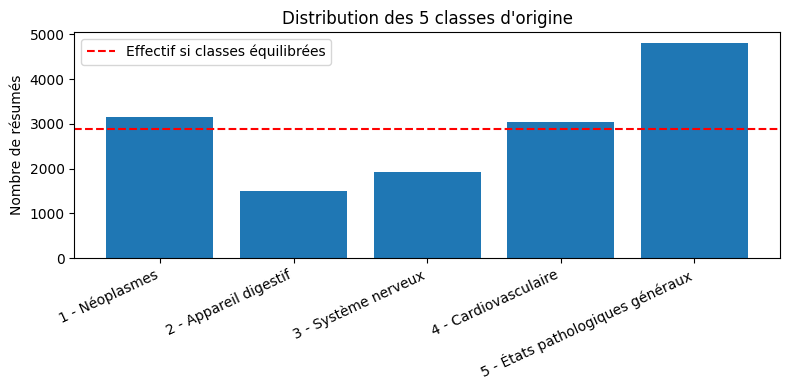

In [6]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, classification_report)

base = "https://raw.githubusercontent.com/EDJINEDJA/Health-Data-modelling/main/lab2/data2/Medical-Abstracts-TC-Corpus-main/"
train = pd.read_csv(base + "medical_tc_train.csv")
test  = pd.read_csv(base + "medical_tc_test.csv")
df = pd.concat([train, test], ignore_index=True)
df["y_bin"] = (df["condition_label"] == 1).astype(int)
print(df.shape)   # attendu : (14438, 3)
import matplotlib.pyplot as plt

noms = {1: "Néoplasmes", 2: "Appareil digestif", 3: "Système nerveux",
        4: "Cardiovasculaire", 5: "États pathologiques généraux"}

effectifs = df["condition_label"].value_counts().sort_index()
distribution = pd.DataFrame({
    "Classe": [f"{k} - {noms[k]}" for k in effectifs.index],
    "Effectif": effectifs.values,
    "Pourcentage": (effectifs / len(df) * 100).round(1).values,
})
print(distribution.to_string(index=False))

print("Ratio de déséquilibre :", round(effectifs.max() / effectifs.min(), 2))
print("Exactitude en prédisant toujours la classe majoritaire :",
      round(effectifs.max() / effectifs.sum(), 3))

plt.figure(figsize=(8, 4))
plt.bar(distribution["Classe"], distribution["Effectif"], color="tab:blue")
plt.axhline(len(df) / 5, color="red", linestyle="--", label="Effectif si classes équilibrées")
plt.xticks(rotation=25, ha="right"); plt.ylabel("Nombre de résumés")
plt.title("Distribution des 5 classes d'origine"); plt.legend(); plt.tight_layout(); plt.show()

# Q 11 : Correction du déséquilibre des classes

In [9]:
import re
import time
import numpy as np
import pandas as pd
import nltk
from nltk.corpus import wordnet as wn
from scipy.sparse import vstack
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, recall_score

necessaires = [
    "X_train_txt5", "y_train5", "X_train5", "X_test5", "y_test5", "vec5"
]
absentes = [nom for nom in necessaires if nom not in globals()]
if absentes:
    raise NameError(
        "Exécutez Q8 avant Q11. Variables manquantes : " + ", ".join(absentes)
    )

rng = np.random.RandomState(42)
y_tr = np.asarray(y_train5)
y_te = np.asarray(y_test5)
txt_tr = np.asarray(X_train_txt5)
X_train_base = X_train5.tocsr()
X_test_base = X_test5.tocsr()

if y_tr.ndim != 1 or y_te.ndim != 1 or txt_tr.ndim != 1:
    raise ValueError("Les textes et les étiquettes doivent être unidimensionnels.")
if len(txt_tr) != len(y_tr) or X_train_base.shape[0] != len(y_tr):
    raise ValueError("Textes, étiquettes et matrice d'entraînement non alignés en taille.")
if X_test_base.shape[0] != len(y_te):
    raise ValueError("Matrice et étiquettes de test non alignées en taille.")
if len(y_tr) == 0 or len(y_te) == 0:
    raise ValueError("Les ensembles d'entraînement et de test doivent être non vides.")

classes = np.unique(y_tr)
effectifs_tr = pd.Series(y_tr).value_counts().sort_index()
cible = int(effectifs_tr.max())  # 3844 sur le découpage de votre Q8.

# 1) Sur-échantillonnage aléatoire : duplication de résumés minoritaires.
idx = list(range(len(y_tr)))
for c in effectifs_tr.index:
    ids = np.flatnonzero(y_tr == c)
    idx.extend(rng.choice(ids, cible - len(ids), replace=True).tolist())
idx = np.asarray(idx, dtype=int)
X_ros, y_ros = X_train_base[idx], y_tr[idx]

# 2) Augmentation de texte : synonymes (10 %) + suppression (10 %).
# Même logique et même ordre des tirages aléatoires que votre code d'origine.
try:
    wn.ensure_loaded()
except LookupError:
    if not nltk.download("wordnet", quiet=True):
        raise RuntimeError("Téléchargement de WordNet impossible.")
    wn.ensure_loaded()

cache = {}


def synonymes(mot):
    if mot not in cache:
        syns = wn.synsets(mot)
        cache[mot] = [
            lemme.name() for lemme in syns[0].lemmas()
            if "_" not in lemme.name() and lemme.name().lower() != mot
        ] if syns else []
    return cache[mot]


def augmenter(texte, p_syn=0.10, p_del=0.10):
    sortie = []
    for mot in texte.split():
        normalise = re.sub(r"[^a-zA-Z]", "", mot).lower()
        if rng.rand() < p_del:
            continue
        if len(normalise) > 3 and rng.rand() < p_syn:
            candidats = synonymes(normalise)
            if candidats:
                sortie.append(candidats[rng.randint(len(candidats))])
                continue
        sortie.append(mot)
    return " ".join(sortie) or texte  # Éviter de créer un texte vide.


print("Original :", txt_tr[0][:200])
print("Augmenté :", augmenter(txt_tr[0])[:200])

aug_txt, aug_y = [], []
for c in effectifs_tr.index:
    ids = np.flatnonzero(y_tr == c)
    for i in rng.choice(ids, cible - len(ids), replace=True):
        aug_txt.append(augmenter(txt_tr[i]))
        aug_y.append(c)

if aug_txt:
    # Pas de fit : vocabulaire et IDF restent ceux du train original de Q8.
    X_aug = vstack([X_train_base, vec5.transform(aug_txt)], format="csr")
    y_aug = np.concatenate([y_tr, np.asarray(aug_y, dtype=y_tr.dtype)])
else:
    X_aug, y_aug = X_train_base.copy(), y_tr.copy()

print("Formes ROS / augmentation :", X_ros.shape, X_aug.shape)
print("Effectifs après ROS :", pd.Series(y_ros).value_counts().sort_index().to_dict())
print("Effectifs après augmentation :", pd.Series(y_aug).value_counts().sort_index().to_dict())

# Reprendre les meilleurs modèles de Q8 si la cellule intégrée a été utilisée.
# Avec votre Q8 initiale, les C retenus étaient LR=1 et SVM=0.1.
if "meilleurs_modeles5" in globals():
    references = {
        nom: clone(meilleurs_modeles5[nom]).set_params(class_weight=None)
        for nom in ("LR", "SVM")
    }
else:
    references = {
        "LR": LogisticRegression(C=1, max_iter=1000, random_state=42),
        "SVM": LinearSVC(C=0.1, random_state=42),
    }


def evaluer_tech(nom, modele, X_fit, y_fit):
    debut = time.perf_counter()
    modele.fit(X_fit, y_fit)
    duree = time.perf_counter() - debut
    pred = modele.predict(X_test_base)
    rappels = recall_score(
        y_te, pred, labels=classes, average=None, zero_division=0
    )
    return {
        "Modèle / technique": nom,
        "Exactitude": accuracy_score(y_te, pred),
        "F1 macro": f1_score(
            y_te, pred, labels=classes, average="macro", zero_division=0
        ),
        "Rappel macro": recall_score(
            y_te, pred, labels=classes, average="macro", zero_division=0
        ),
        **{f"Rappel cl.{c}": r for c, r in zip(classes, rappels)},
        "Temps (s)": duree,
    }


# La référence sans correction n'est pas une troisième technique de rééquilibrage.
# Deux modèles x (une référence + deux techniques) = six lignes.
lignes = []
for nom, reference in references.items():
    for technique, X_fit, y_fit in (
        ("sans correction", X_train_base, y_tr),
        ("sur-échantillonnage aléatoire", X_ros, y_ros),
        ("augmentation de texte", X_aug, y_aug),
    ):
        lignes.append(evaluer_tech(
            f"{nom} - {technique}", clone(reference), X_fit, y_fit
        ))

resultats_q11 = pd.DataFrame(lignes).set_index("Modèle / technique")
print(resultats_q11.round(3).to_string())

Original : Job's syndrome: a rare cause of recurrent lung abscess in childhood. A clinical syndrome characterized by recurrent staphylococcal infection of the skin and respiratory tract from birth was described 
Augmenté : Job's syndrome: a rare cause of recurrent lung abscess in childhood. clinical syndrome characterized by recurrent staphylococcal infection the skin and respiratory tract from birth was described in 19
Formes ROS / augmentation : (19220, 11724) (19220, 11724)
Effectifs après ROS : {1: 3844, 2: 3844, 3: 3844, 4: 3844, 5: 3844}
Effectifs après augmentation : {1: 3844, 2: 3844, 3: 3844, 4: 3844, 5: 3844}
                                     Exactitude  F1 macro  Rappel macro  Rappel cl.1  Rappel cl.2  Rappel cl.3  Rappel cl.4  Rappel cl.5  Temps (s)
Modèle / technique                                                                                                                                 
LR - sans correction                      0.565     0.540         0.525      

# Q 12 :

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              AdaBoostClassifier, StackingClassifier)
from xgboost import XGBClassifier

rng = np.random.RandomState(0)
perturber = lambda t: " ".join(w for w in t.split() if rng.rand() > 0.2)
X_test_pert = vec5.transform([perturber(t) for t in X_test_txt5.values])

def ic_bootstrap(y, p, n=1000):
    r = np.random.RandomState(1); s = []
    for _ in range(n):
        i = r.randint(0, len(y), len(y)); s.append(f1_score(y[i], p[i], average="macro"))
    return np.percentile(s, [2.5, 97.5])

modeles = {
 "Arbre de décision": DecisionTreeClassifier(random_state=42),
 "Bagging (arbres)": BaggingClassifier(DecisionTreeClassifier(), n_estimators=25, random_state=42),
 "Forêt aléatoire": RandomForestClassifier(n_estimators=200, random_state=42),   # lent : n_jobs=-1 aide
 "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
 "XGBoost": XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.1, tree_method="hist", random_state=42),
 "Stacking": StackingClassifier(
     estimators=[("lr", LogisticRegression(C=1, max_iter=1000)), ("svm", LinearSVC(C=0.1)),
                 ("rf", RandomForestClassifier(n_estimators=100, random_state=42))],
     final_estimator=LogisticRegression(max_iter=1000), cv=3),
 "Régression logistique": LogisticRegression(C=1, max_iter=1000, random_state=42),
 "SVM linéaire": LinearSVC(C=0.1, random_state=42),
}

lignes = []
for nom, m in modeles.items():
    dec = 1 if nom == "XGBoost" else 0            # XGBoost veut des étiquettes 0 à 4
    ytr_, yte_ = y_train5.values - dec, y_test5.values - dec
    t0 = time.time(); m.fit(X_train5, ytr_); duree = time.time() - t0
    p = m.predict(X_test5); lo, hi = ic_bootstrap(yte_, p)
    lignes.append({"Modèle": nom, "Temps (s)": round(duree, 1),
                   "Exactitude test": accuracy_score(yte_, p),
                   "F1 macro": f1_score(yte_, p, average="macro"), "IC95 bas": lo, "IC95 haut": hi,
                   "Exactitude train": accuracy_score(ytr_, m.predict(X_train5)),
                   "F1 macro test perturbé": f1_score(yte_, m.predict(X_test_pert), average="macro")})
    print(lignes[-1])
print(pd.DataFrame(lignes).set_index("Modèle").round(3).to_string())

{'Modèle': 'Arbre de décision', 'Temps (s)': 29.5, 'Exactitude test': 0.4144736842105263, 'F1 macro': 0.4066699361738679, 'IC95 bas': np.float64(0.3887124158245858), 'IC95 haut': np.float64(0.42514252937330504), 'Exactitude train': 0.8191341991341992, 'F1 macro test perturbé': 0.456111698341386}
{'Modèle': 'Bagging (arbres)', 'Temps (s)': 316.0, 'Exactitude test': 0.4660664819944598, 'F1 macro': 0.4486658789282556, 'IC95 bas': np.float64(0.4307088204304091), 'IC95 haut': np.float64(0.4663488340570216), 'Exactitude train': 0.8184415584415584, 'F1 macro test perturbé': 0.47823541625010507}
{'Modèle': 'Forêt aléatoire', 'Temps (s)': 774.9, 'Exactitude test': 0.47541551246537395, 'F1 macro': 0.444984429251145, 'IC95 bas': np.float64(0.4261455245574663), 'IC95 haut': np.float64(0.4622910771225815), 'Exactitude train': 0.8191341991341992, 'F1 macro test perturbé': 0.4509106881335251}
{'Modèle': 'AdaBoost', 'Temps (s)': 22.1, 'Exactitude test': 0.4916897506925208, 'F1 macro': 0.35612012063258

In [10]:
# À ajouter pour le rapport : mesurer l'effet des doublons
print("Textes dupliqués :", df["medical_abstract"].duplicated().sum())
print("Textes à plusieurs étiquettes :", (df.groupby("medical_abstract")["condition_label"].nunique() > 1).sum())
textes_train = set(X_train_txt5.values)
est_doublon = np.array([t in textes_train for t in X_test_txt5.values])
print("Test présent dans le train :", est_doublon.sum(), round(est_doublon.mean(), 3))
# Pour chaque modèle ajusté : exactitude séparée
# accuracy_score(y_test5[est_doublon], pred[est_doublon])  /  accuracy_score(y_test5[~est_doublon], pred[~est_doublon])

Textes dupliqués : 3211
Textes à plusieurs étiquettes : 2929
Test présent dans le train : 1016 0.352
